<img src="https://raw.githubusercontent.com/carubbi/MQ/b58af070c45fb17b77640c06c0016859ad366b4d/notebooks/assets/imgs/UNIFOR_logo.png" width="400">
<br>
<b>
<font size="6" face="arial" color="blue">
    Graduação em Ciência da Computação
</font>
</b>
<br>
<b>
<font size="4" face="arial">
    Disciplina: Métodos Quantitativos em Computação
</font>
</b>

**Orientador: Prof. Me. Ricardo Carubbi** <br>
*Docente da Graduação e Pós-Graduação em Ciência de Dados e Inteligência Artificial*<br>
*Laboratório de Ciência de Dados e Inteligência Artificial*<br>
*Universidade de Fortaleza*<br>

# Unidade II — Semana 04: Distribuições contínuas

**Aula 7 — Uniforme e Exponencial** · **Aula 8 — Normal**

Resolução com cálculos, resultados e interpretações.

## 1. Objetivos de aprendizagem

Ao final da aula, o aluno será capaz de:

- definir as variáveis aleatórias dos fenômenos apresentados, com unidade de medida e suporte;
- distinguir os mecanismos Uniforme e Exponencial e interpretar seus parâmetros;
- relacionar taxa de ocorrências e tempo de espera sob os pressupostos de um processo de Poisson;
- calcular probabilidades, esperanças e variâncias nos modelos trabalhados;
- interpretar os parâmetros da Normal, padronizar valores e calcular probabilidades computacionalmente;
- conferir cálculos com SciPy e interpretar resultados teóricos, gráficos e simulações.

## 2. Agenda

**Aula 7 — Uniforme e Exponencial, 100 min**

1. Revisão de variáveis contínuas: variáveis, unidades, suportes e probabilidade como área — 10 min
2. Uniforme: mecanismo, parâmetros, densidade, acumulada, esperança e variância; implementação e simulação — 35 min
3. Exponencial: mecanismo, taxa, densidade, acumulada, esperança e variância; implementação e simulação — 40 min
4. Relação entre processo de Poisson e tempo de espera; falta de memória — 15 min

**Aula 8 — Normal, 70 min no notebook**

1. Modelo Normal: suporte, parâmetros, densidade e momentos; implementação e conferência com SciPy — 30 min
2. Padronização e interpretação do escore z; implementação e conferência com SciPy — 15 min
3. Probabilidades de intervalos e caudas com SciPy; conferência e interpretação gráfica — 25 min

Os 30 minutos finais da Aula 8 são destinados ao segundo acompanhamento da AP2, fora deste notebook.

In [1]:
# IMPORTAÇÕES
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from IPython.display import display

# CONFIGURAÇÃO DOS GRÁFICOS
plt.rcParams['figure.figsize'] = (10, 4)
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.alpha'] = 0.2
plt.rcParams['font.size'] = 11

# SIMULAÇÕES REPRODUZÍVEIS
semente = 42
n_sim = 10000
rng = np.random.default_rng(semente)

Matplotlib is building the font cache; this may take a moment.


## 3. Revisão de variáveis contínuas

### 3.1. Contexto

Um ponteiro gira em um círculo. Podemos registrar o **setor** em que ele para ou o **ângulo** em relação à horizontal à direita. Com duas ou quatro divisões, o setor assume um conjunto finito de valores; ao registrar o ângulo, passamos a uma variável contínua. Admitimos que nenhuma região do círculo é favorecida (Barbetta; Reis; Bornia, 2010, p. 141–143).

<div style="display: flex; flex-wrap: wrap; justify-content: center; align-items: center; gap: 20px; margin: 20px auto; max-width: 100%;">
  <div style="flex: 0 1 200px; max-width: 100%;">
    <img alt="Ponteiro com dois setores" width="200" style="display: block; width: 100%; max-width: 200px; height: auto; margin: 0 auto;" src="../assets/imgs/u2_s04/ponteiro_dois_setores.png">
  </div>
  <div style="flex: 0 1 200px; max-width: 100%;">
    <img alt="Ponteiro com quatro setores" width="200" style="display: block; width: 100%; max-width: 200px; height: auto; margin: 0 auto;" src="../assets/imgs/u2_s04/ponteiro_quatro_setores.png">
  </div>
  <div style="flex: 0 1 240px; max-width: 100%;">
    <img alt="Ângulo observado na posição final" width="240" style="display: block; width: 100%; max-width: 240px; height: auto; margin: 0 auto;" src="../assets/imgs/u2_s04/ponteiro_angulo.png">
  </div>
</div>

*Figura 1 — Do registro do setor ao registro do ângulo. Recortes dos Exemplos 6.1(a–b) e 6.2. Fonte: Barbetta, Reis e Bornia (2010, p. 141, 143; PDF, p. 142, 144).*

**Pergunta:** qual é a probabilidade de o ângulo ficar entre 30° e 60°?

### 3.2. Fundamentação formal

O espaço amostral $\Omega$ reúne as posições finais possíveis; $\omega\in\Omega$ é uma dessas posições. A variável $X:\Omega\to[0,360)$ associa a cada posição seu ângulo, em graus. O símbolo $X$ representa a variável; $x$ representa um valor observado.

Para uma variável contínua com densidade $f_X$, as probabilidades correspondem a áreas:

$$
f_X(x)\geq0,\qquad \int_{-\infty}^{\infty} f_X(x)\,dx=1.
\tag{7.1}
$$

Aqui, $f_X(x)$ é a densidade no valor $x$ e a integral é a área total. No círculo sem região preferida, a densidade é constante em $[0,360)$ e vale $1/360$ por grau; fora desse intervalo, vale zero.

A função de distribuição acumulada é

$$
F_X(x)=\mathbb{P}(X\leq x)=\int_{-\infty}^{x}f_X(v)\,dv.
\tag{7.2}
$$

$F_X(x)$ é a probabilidade acumulada até $x$; $v$ é a variável de integração. Densidade tem unidade inversa à da variável; probabilidade e acumulada não têm unidade.

Para limites $c<d$,

$$
\mathbb{P}(c<X\leq d)=F_X(d)-F_X(c),\qquad \mathbb{P}(X=x)=0.
\tag{7.3}
$$

$c$ e $d$ delimitam o evento. A inclusão dos extremos não altera a probabilidade, pois um ponto tem área nula. Isso não impede que uma medição arredondada apresente valores repetidos (Barbetta; Reis; Bornia, 2010, p. 141–145; Pinheiro et al., 2009, p. 111–112).

<div style="max-width: 100%; margin: 20px auto; text-align: center;">
  <img alt="Densidade constante e área de um evento" width="720" style="display: block; width: 100%; max-width: 720px; height: auto; margin: 0 auto;" src="../assets/imgs/u2_s04/figura_6_4_densidade_area.png">
</div>

*Figura 2 — A altura da densidade e a área de um intervalo representam quantidades distintas. Recorte da Figura 6.4. Fonte: Barbetta, Reis e Bornia (2010, p. 143; PDF, p. 144).*

Para variáveis com momentos finitos, a esperança e a variância são

$$
\mathbb{E}[X]=\int_{-\infty}^{\infty}x f_X(x)\,dx,
\qquad
\operatorname{Var}(X)=\mathbb{E}\!\left[(X-\mathbb{E}[X])^2\right].
\tag{7.4}
$$

$\mathbb{E}[X]$ descreve o centro da distribuição, na unidade de $X$; $\operatorname{Var}(X)$ descreve a dispersão, na unidade ao quadrado. Usaremos as expressões próprias de cada modelo, sem desenvolver integrações longas (Barbetta; Reis; Bornia, 2010, p. 145–146).

### 3.3. Aplicação e interpretação

<div style="max-width: 100%; margin: 20px auto; text-align: center;">
  <img alt="Intervalo de 30 a 60 graus" width="360" style="display: block; width: 100%; max-width: 360px; height: auto; margin: 0 auto;" src="../assets/imgs/u2_s04/ponteiro_intervalo_30_60.png">
</div>

*Figura 3 — Região do evento entre 30° e 60°. Fonte: Barbetta, Reis e Bornia (2010, p. 143; PDF, p. 144).*

A variável é o ângulo, a unidade é o grau e os valores possíveis estão em $[0,360)$. A região solicitada ocupa 30 dos 360 graus: $\mathbb{P}(30<X<60)=(60-30)/360=1/12\approx0{,}0833$. O mesmo resultado é obtido por $F_X(60)-F_X(30)$.

**Evidência:** explicar por que $1/360$ é uma densidade e por que a probabilidade de um único ângulo é zero.

## 4. Distribuição Uniforme

### 4.1. Contexto

Um sistema leva entre 20 e 24 segundos para executar uma tarefa. O enunciado admite uma distribuição Uniforme: subintervalos de mesma amplitude têm a mesma probabilidade. O intervalo observado, sozinho, não estabelece essa hipótese (Barbetta; Reis; Bornia, 2010, p. 146–147, exercício 2).

**Perguntas:** qual é a probabilidade de ultrapassar 23 segundos? Qual é o tempo médio e qual é sua variância?

### 4.2. Fundamentação formal

$\Omega$ reúne as execuções possíveis da tarefa e $\omega$ é uma execução. A variável $U:\Omega\to[a,b]$ associa a cada execução seu tempo; $u$ é um valor observado. Os parâmetros $a<b$ são os limites, na mesma unidade de $U$. Escrevemos $U\sim\operatorname{Uniforme}(a,b)$.

$$
f_U(u)=\begin{cases}
\dfrac{1}{b-a},&a\leq u\leq b,\\
0,&\text{caso contrário}.
\end{cases}
\tag{7.5}
$$

$f_U(u)$ é a densidade; $b-a$ é a amplitude do suporte. Para tempos em segundos, a densidade tem unidade $\mathrm{s}^{-1}$.

$$
F_U(u)=\begin{cases}
0,&u<a,\\
\dfrac{u-a}{b-a},&a\leq u<b,\\
1,&u\geq b.
\end{cases}
\tag{7.6}
$$

$F_U(u)$ acumula a probabilidade até $u$. Usamos a diferença de acumuladas para intervalos e $1-F_U(u)$ para a cauda direita. Essas regras também tratam limites fora do suporte.

$$
\mathbb{E}[U]=\frac{a+b}{2},\qquad
\operatorname{Var}(U)=\frac{(b-a)^2}{12}.
\tag{7.7}
$$

A esperança é o ponto médio, em segundos; a variância depende da amplitude, em segundos ao quadrado. Os mesmos símbolos $a$ e $b$ representam os limites nas três expressões (Barbetta; Reis; Bornia, 2010, p. 148; Morettin; Bussab, 2010, p. 174–175).

### 4.3. Implementação sem pacote estatístico

As funções retornam valores individuais comparáveis a `pdf`, `cdf`, `sf`, `mean` e `var`. A probabilidade de intervalo usa a diferença entre duas acumuladas. Primeiro definimos as funções gerais; depois aplicamos os parâmetros do exercício.

In [2]:
# DENSIDADE UNIFORME
def dens_unif(u, a, b):
    if a >= b:
        raise ValueError('É necessário a < b.')
    if u < a or u > b:
        return 0.0
    return 1 / (b - a)

In [3]:
# ACUMULADA UNIFORME
def acum_unif(u, a, b):
    if a >= b:
        raise ValueError('É necessário a < b.')
    if u < a:
        return 0.0
    elif u >= b:
        return 1.0
    else:
        return (u - a) / (b - a)

# CAUDA DIREITA
def cauda_unif(u, a, b):
    return 1 - acum_unif(u, a, b)

# PROBABILIDADE DE INTERVALO
def intervalo_unif(inf, sup, a, b):
    if inf >= sup:
        raise ValueError('É necessário limite inferior < superior.')
    return acum_unif(sup, a, b) - acum_unif(inf, a, b)

In [4]:
# ESPERANÇA UNIFORME
def esp_unif(a, b):
    if a >= b:
        raise ValueError('É necessário a < b.')
    return (a + b) / 2

# VARIÂNCIA UNIFORME
def var_unif(a, b):
    if a >= b:
        raise ValueError('É necessário a < b.')
    return (b - a) ** 2 / 12

# PARÂMETROS DA APLICAÇÃO
a = 20
b = 24
limite_u = 23

# CÁLCULOS DO EXERCÍCIO
prob_u = cauda_unif(limite_u, a, b)
media_u = esp_unif(a, b)
variancia_u = var_unif(a, b)

### 4.4. Implementação com pacotes

No SciPy, `loc=a` é o limite inferior e `scale=b-a` é a amplitude. `pdf` retorna densidade; `cdf`, probabilidade à esquerda; `sf`, probabilidade à direita; `mean` e `var`, os momentos. Usar `scale=b` produziria outro modelo (SciPy Community, [s. d.], verbete [`scipy.stats.uniform`](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.uniform.html)).

In [5]:
# MODELO E CÁLCULOS COM SCIPY
modelo_u = stats.uniform(loc=a, scale=b - a)
prob_u_scipy = modelo_u.sf(limite_u)
media_u_scipy = modelo_u.mean()
variancia_u_scipy = modelo_u.var()

# COMPARAÇÃO DOS RESULTADOS
comparacao_u = pd.DataFrame({
    'Quantidade': ['P(U > 23)', 'Esperança (s)', 'Variância (s²)'],
    'Sem pacote estatístico': [prob_u, media_u, variancia_u],
    'SciPy': [prob_u_scipy, media_u_scipy, variancia_u_scipy]
})
display(comparacao_u)

,Quantidade,Sem pacote estatístico,SciPy
0,P(U > 23),0.250000,0.250000
1,Esperança (s),22.000000,22.000000
2,Variância (s²),1.333333,1.333333


In [6]:
# VERIFICAÇÃO DO SUPORTE
valores_u = [19, 20, 22, 23, 24, 25]
linhas_u = []
for valor in valores_u:
    linha = [valor, dens_unif(valor, a, b), modelo_u.pdf(valor),
             acum_unif(valor, a, b), modelo_u.cdf(valor),
             cauda_unif(valor, a, b), modelo_u.sf(valor)]
    linhas_u.append(linha)

# APRESENTAÇÃO DA CONFERÊNCIA
colunas_u = ['Tempo (s)', 'Densidade manual', 'Densidade SciPy',
             'Acumulada manual', 'Acumulada SciPy', 'Cauda manual', 'Cauda SciPy']
display(pd.DataFrame(linhas_u, columns=colunas_u))

,Tempo (s),Densidade manual,Densidade SciPy,Acumulada manual,Acumulada SciPy,Cauda manual,Cauda SciPy
0,19,0.00,0.00,0.00,0.00,1.00,1.00
1,20,0.25,0.25,0.00,0.00,1.00,1.00
2,22,0.25,0.25,0.50,0.50,0.50,0.50
3,23,0.25,0.25,0.75,0.75,0.25,0.25
4,24,0.25,0.25,1.00,1.00,0.00,0.00
5,25,0.00,0.00,1.00,1.00,0.00,0.00


**Simulação pronta.** Serão geradas 10.000 execuções. A seleção `amostra_u > limite_u` produz um vetor de condições; `count_nonzero` conta as condições verdadeiras. A frequência é a contagem dividida pelo tamanho da amostra. A mesma semente reproduz a sequência quando o notebook é executado do início ao fim.

In [7]:
# GERAÇÃO DAS EXECUÇÕES
amostra_u = modelo_u.rvs(size=n_sim, random_state=rng)

# CONTAGEM DO EVENTO
contagem_u = np.count_nonzero(amostra_u > limite_u)
freq_u = contagem_u / n_sim

# COMPARAÇÃO TEÓRICA E SIMULADA
print(f'Número de execuções: {n_sim}')
print(f'Execuções acima de 23 s: {contagem_u}')
print(f'Frequência simulada: {freq_u:.4f}')
print(f'Probabilidade teórica: {prob_u_scipy:.4f}')

Número de execuções: 10000
Execuções acima de 23 s: 2442
Frequência simulada: 0.2442
Probabilidade teórica: 0.2500


### 4.5. Aplicação e interpretação

**Exercício 2, capítulo 6, enunciado e itens (a)–(c)** (Barbetta; Reis; Bornia, 2010, p. 146–147).

A densidade vale **0,25 s⁻¹** entre 20 e 24 segundos e zero fora desse intervalo. A área total é `4 × 0,25 = 1`.

- **(a)** A cauda acima de 23 segundos tem largura 1 segundo: **P(U > 23) = 0,25**. A acumulada em 23 é 0,75; seu complemento fornece a probabilidade solicitada.
- **(b)** A esperança é **22 segundos**.
- **(c)** A variância é **4/3 ≈ 1,3333 s²**. Sua unidade é diferente da unidade do tempo.

A densidade em 23 e a probabilidade acima de 23 têm aqui o mesmo valor numérico, mas representam quantidades diferentes. A frequência simulada aproxima a probabilidade; a diferença observada decorre da amostragem.

**Evidências:** identificar o evento na densidade, localizar a acumulada em 23 e comparar funções, pacote e frequência simulada.

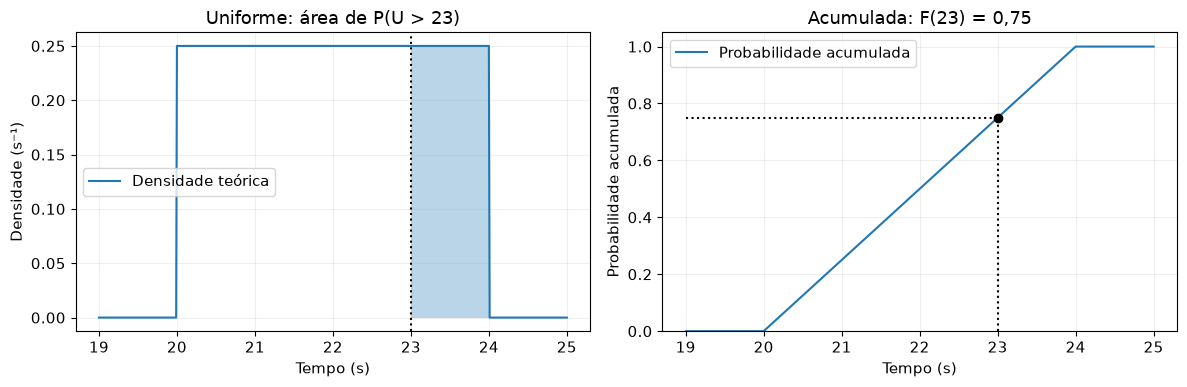

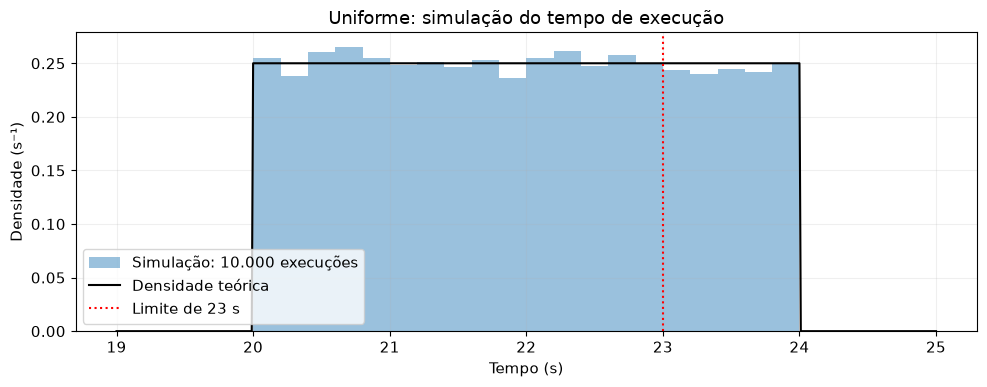

In [8]:
# PONTOS PARA AS CURVAS DA UNIFORME
x_u = np.linspace(19, 25, 601)

# DENSIDADE E EVENTO
fig, eixos = plt.subplots(1, 2, figsize=(12, 4))
eixos[0].plot(x_u, modelo_u.pdf(x_u), label='Densidade teórica')
x_area_u = np.linspace(limite_u, b, 101)
eixos[0].fill_between(x_area_u, modelo_u.pdf(x_area_u), alpha=0.3)
eixos[0].axvline(limite_u, color='black', linestyle=':')
eixos[0].set(title='Uniforme: área de P(U > 23)', xlabel='Tempo (s)', ylabel='Densidade (s⁻¹)')
eixos[0].legend()

# ACUMULADA E COMPLEMENTO
valor_cdf_u = modelo_u.cdf(limite_u)
eixos[1].plot(x_u, modelo_u.cdf(x_u), label='Probabilidade acumulada')
eixos[1].plot(limite_u, valor_cdf_u, 'o', color='black')
eixos[1].vlines(limite_u, 0, valor_cdf_u, color='black', linestyle=':')
eixos[1].hlines(valor_cdf_u, 19, limite_u, color='black', linestyle=':')
eixos[1].set(title='Acumulada: F(23) = 0,75', xlabel='Tempo (s)', ylabel='Probabilidade acumulada', ylim=(0, 1.05))
eixos[1].legend()
fig.tight_layout()
plt.show()

# HISTOGRAMA E DENSIDADE TEÓRICA
fig, ax = plt.subplots()
ax.hist(amostra_u, bins=20, density=True, alpha=0.45, label='Simulação: 10.000 execuções')
ax.plot(x_u, modelo_u.pdf(x_u), color='black', label='Densidade teórica')
ax.axvline(limite_u, color='red', linestyle=':', label='Limite de 23 s')
ax.set(title='Uniforme: simulação do tempo de execução', xlabel='Tempo (s)', ylabel='Densidade (s⁻¹)')
ax.legend()
fig.tight_layout()
plt.show()

*Figuras 4 e 5 — Densidade e acumulada do exercício 2; histograma das mesmas execuções simuladas. Elaboração para a aula, com os parâmetros de Barbetta, Reis e Bornia (2010, p. 146–147). A probabilidade é área sob a densidade; na acumulada, lemos a altura.*

## 5. Distribuição Exponencial

### 5.1. Contexto

O tempo de vida de um transistor segue uma Exponencial com média de 500 horas. **Qual é a probabilidade de durar mais de 500 horas? E entre 300 e 1000 horas?** (Barbetta; Reis; Bornia, 2010, p. 152, exercício 6, itens a–b).

O modelo admite taxa de falha constante, sem envelhecimento. Essa hipótese precisa ser avaliada em uma aplicação real: conhecer apenas o tempo médio não justifica uma Exponencial.

### 5.2. Fundamentação formal

$\Omega$ reúne as trajetórias de funcionamento dos transistores e $\omega$ é uma dessas trajetórias. A variável $T:\Omega\to[0,\infty)$ registra o tempo até a falha, em horas; $t$ é um tempo observado. A taxa $\lambda>0$ é medida em $\mathrm{h}^{-1}$. Escrevemos $T\sim\operatorname{Exp}(\lambda)$.

$$
f_T(t)=\begin{cases}\lambda e^{-\lambda t},&t\geq0,\\0,&t<0.\end{cases}
\tag{7.8}
$$

$f_T(t)$ é a densidade em $t$ e $e$ é a base da função exponencial. O produto $\lambda t$ não tem unidade.

$$
F_T(t)=\begin{cases}1-e^{-\lambda t},&t\geq0,\\0,&t<0.\end{cases}
\tag{7.9}
$$

$F_T(t)$ é a probabilidade de a falha ocorrer até $t$. Sua complementar é a **sobrevivência**:

$$
S_T(t)=\mathbb{P}(T>t)=\begin{cases}e^{-\lambda t},&t\geq0,\\1,&t<0.\end{cases}
\tag{7.10}
$$

$S_T(t)$ é a probabilidade de o transistor ainda funcionar após $t$. Para limites $c<d$, usamos $F_T(d)-F_T(c)$; quando ambos são não negativos, também podemos usar $S_T(c)-S_T(d)$.

$$
\mathbb{E}[T]=\frac{1}{\lambda},\qquad \operatorname{Var}(T)=\frac{1}{\lambda^2}.
\tag{7.11}
$$

A esperança está em horas; a variância, em horas ao quadrado. No exercício, a **escala** é $1/\lambda=500$ horas e a **taxa** é $\lambda=1/500=0{,}002\ \mathrm{h}^{-1}$. Morettin e Bussab utilizam $\beta$ para essa escala: $\beta=1/\lambda$ (Barbetta; Reis; Bornia, 2010, p. 149–152; Morettin; Bussab, 2010, p. 181–182; Pinheiro et al., 2009, p. 117–118).

### 5.3. Implementação sem pacote estatístico

Implementaremos densidade, acumulada, sobrevivência, probabilidade de intervalo e momentos. As funções recebem a **taxa**, verificam sua positividade e tratam valores abaixo de zero.

In [9]:
# DENSIDADE EXPONENCIAL
def dens_exp(t, taxa):
    if taxa <= 0:
        raise ValueError('A taxa deve ser positiva.')
    if t < 0:
        return 0.0
    return taxa * math.exp(-taxa * t)

# ACUMULADA EXPONENCIAL
def acum_exp(t, taxa):
    if taxa <= 0:
        raise ValueError('A taxa deve ser positiva.')
    if t < 0:
        return 0.0
    return 1 - math.exp(-taxa * t)

# SOBREVIVÊNCIA EXPONENCIAL
def cauda_exp(t, taxa):
    if taxa <= 0:
        raise ValueError('A taxa deve ser positiva.')
    if t < 0:
        return 1.0
    return math.exp(-taxa * t)

In [10]:
# PROBABILIDADE DE INTERVALO
def intervalo_exp(inf, sup, taxa):
    if inf >= sup:
        raise ValueError('É necessário limite inferior < superior.')
    return cauda_exp(inf, taxa) - cauda_exp(sup, taxa)

# ESPERANÇA EXPONENCIAL
def esp_exp(taxa):
    if taxa <= 0:
        raise ValueError('A taxa deve ser positiva.')
    return 1 / taxa

# VARIÂNCIA EXPONENCIAL
def var_exp(taxa):
    if taxa <= 0:
        raise ValueError('A taxa deve ser positiva.')
    return 1 / taxa ** 2

# PARÂMETROS DO TRANSISTOR
media_t = 500
taxa_t = 1 / media_t

# CÁLCULOS DOS ITENS A E B
prob_t_a = cauda_exp(500, taxa_t)
prob_t_b = intervalo_exp(300, 1000, taxa_t)
esperanca_t = esp_exp(taxa_t)
variancia_t = var_exp(taxa_t)

### 5.4. Implementação com pacotes

Use `stats.expon(loc=0, scale=1/taxa_t)`. `scale` recebe o tempo médio, não a taxa. O método `sf` calcula diretamente a sobrevivência; a probabilidade de intervalo pode ser conferida pela diferença de `cdf` (SciPy Community, [s. d.], verbete [`scipy.stats.expon`](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.expon.html)).

In [11]:
# MODELO E PROBABILIDADES COM SCIPY
modelo_t = stats.expon(loc=0, scale=1 / taxa_t)
prob_t_a_scipy = modelo_t.sf(500)
prob_t_b_scipy = modelo_t.cdf(1000) - modelo_t.cdf(300)

# COMPARAÇÃO DOS RESULTADOS
comparacao_t = pd.DataFrame({
    'Quantidade': ['P(T > 500)', 'P(300 < T < 1000)', 'Esperança (h)', 'Variância (h²)'],
    'Sem pacote estatístico': [prob_t_a, prob_t_b, esperanca_t, variancia_t],
    'SciPy': [prob_t_a_scipy, prob_t_b_scipy, modelo_t.mean(), modelo_t.var()]
})
display(comparacao_t)

,Quantidade,Sem pacote estatístico,SciPy
0,P(T > 500),0.367879,0.367879
1,P(300 < T < 1000),0.413476,0.413476
2,Esperança (h),500.000000,500.000000
3,Variância (h²),250000.000000,250000.000000


In [12]:
# CONFERÊNCIA DENTRO E FORA DO SUPORTE
valores_t = [-100, 0, 300, 500, 1000]
linhas_t = []
for valor in valores_t:
    linha = [valor, dens_exp(valor, taxa_t), modelo_t.pdf(valor),
             acum_exp(valor, taxa_t), modelo_t.cdf(valor),
             cauda_exp(valor, taxa_t), modelo_t.sf(valor)]
    linhas_t.append(linha)

# APRESENTAÇÃO DA CONFERÊNCIA
colunas_t = ['Tempo (h)', 'Densidade manual', 'Densidade SciPy',
             'Acumulada manual', 'Acumulada SciPy', 'Cauda manual', 'Cauda SciPy']
display(pd.DataFrame(linhas_t, columns=colunas_t))

# SIMULAÇÃO DAS VIDAS ÚTEIS
amostra_t = modelo_t.rvs(size=n_sim, random_state=rng)
contagem_t_a = np.count_nonzero(amostra_t > 500)
evento_t_b = (amostra_t > 300) & (amostra_t < 1000)
contagem_t_b = np.count_nonzero(evento_t_b)
freq_t_a = contagem_t_a / n_sim
freq_t_b = contagem_t_b / n_sim

# FREQUÊNCIAS DOS MESMOS EVENTOS
print(f'Número de transistores: {n_sim}')
print(f'Mais de 500 h: {contagem_t_a}; frequência = {freq_t_a:.4f}')
print(f'Entre 300 e 1000 h: {contagem_t_b}; frequência = {freq_t_b:.4f}')
print(f'Probabilidades teóricas: {prob_t_a_scipy:.4f} e {prob_t_b_scipy:.4f}')

,Tempo (h),Densidade manual,Densidade SciPy,Acumulada manual,Acumulada SciPy,Cauda manual,Cauda SciPy
0,-100,0.000000,0.000000,0.000000,0.000000,1.000000,1.000000
1,0,0.002000,0.002000,0.000000,0.000000,1.000000,1.000000
2,300,0.001098,0.001098,0.451188,0.451188,0.548812,0.548812
3,500,0.000736,0.000736,0.632121,0.632121,0.367879,0.367879
4,1000,0.000271,0.000271,0.864665,0.864665,0.135335,0.135335


Número de transistores: 10000
Mais de 500 h: 3707; frequência = 0.3707
Entre 300 e 1000 h: 4164; frequência = 0.4164
Probabilidades teóricas: 0.3679 e 0.4135


### 5.5. Aplicação e interpretação

**Exercício 6, capítulo 6, itens (a)–(b)** (Barbetta; Reis; Bornia, 2010, p. 152).

- **(a)** P(T > 500) ≈ **0,3679**: cerca de 36,79% dos transistores duram mais que o tempo médio, sob o modelo.
- **(b)** P(300 < T < 1000) ≈ **0,4135**: cerca de 41,35% têm vida nesse intervalo.

A média é **500 h** e a variância é **250.000 h²**. A distribuição é assimétrica: o tempo médio não divide a probabilidade ao meio. As frequências simuladas oscilam em torno das probabilidades teóricas; uma amostra finita não confirma, por si só, a adequação do modelo a transistores reais.

**Evidências:** comparar os dois eventos nas funções, nos métodos do SciPy e na simulação; identificar as áreas correspondentes e distinguir taxa de tempo médio.

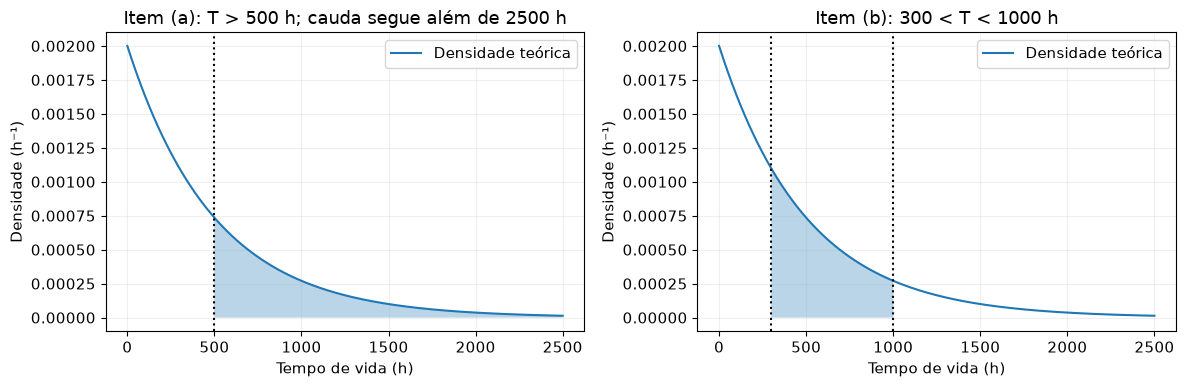

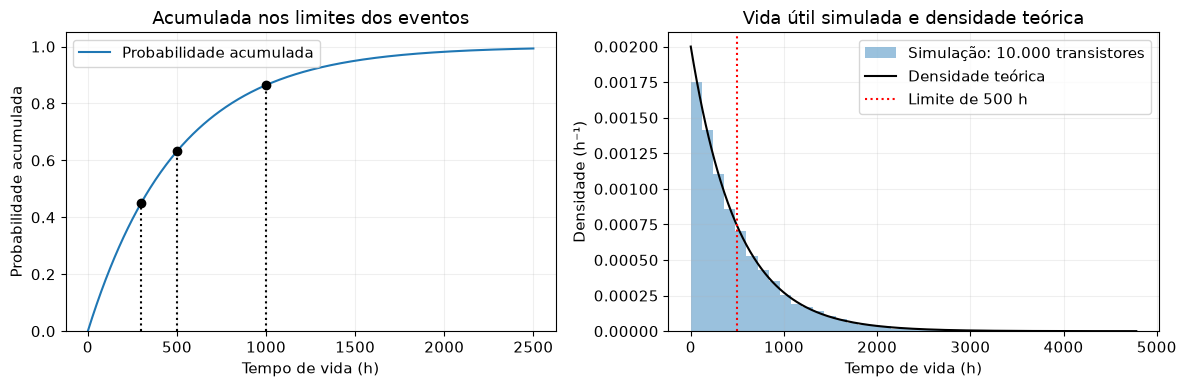

In [13]:
# PONTOS PARA AS CURVAS DA EXPONENCIAL
x_t = np.linspace(0, 2500, 501)

# ÁREAS DOS ITENS A E B
fig, eixos = plt.subplots(1, 2, figsize=(12, 4))
for ax in eixos:
    ax.plot(x_t, modelo_t.pdf(x_t), label='Densidade teórica')
    ax.set(xlabel='Tempo de vida (h)', ylabel='Densidade (h⁻¹)')
    ax.legend()
x_area_t_a = np.linspace(500, 2500, 401)
x_area_t_b = np.linspace(300, 1000, 141)
eixos[0].fill_between(x_area_t_a, modelo_t.pdf(x_area_t_a), alpha=0.3)
eixos[0].axvline(500, color='black', linestyle=':')
eixos[0].set_title('Item (a): T > 500 h; cauda segue além de 2500 h')
eixos[1].fill_between(x_area_t_b, modelo_t.pdf(x_area_t_b), alpha=0.3)
eixos[1].axvline(300, color='black', linestyle=':')
eixos[1].axvline(1000, color='black', linestyle=':')
eixos[1].set_title('Item (b): 300 < T < 1000 h')
fig.tight_layout()
plt.show()

# ACUMULADA DOS LIMITES E HISTOGRAMA
fig, eixos = plt.subplots(1, 2, figsize=(12, 4))
eixos[0].plot(x_t, modelo_t.cdf(x_t), label='Probabilidade acumulada')
for limite in [300, 500, 1000]:
    altura = modelo_t.cdf(limite)
    eixos[0].plot(limite, altura, 'o', color='black')
    eixos[0].vlines(limite, 0, altura, color='black', linestyle=':')
eixos[0].set(title='Acumulada nos limites dos eventos', xlabel='Tempo de vida (h)', ylabel='Probabilidade acumulada', ylim=(0, 1.05))
eixos[0].legend()
eixos[1].hist(amostra_t, bins=40, density=True, alpha=0.45, label='Simulação: 10.000 transistores')
x_hist_t = np.linspace(0, np.max(amostra_t), 600)
eixos[1].plot(x_hist_t, modelo_t.pdf(x_hist_t), color='black', label='Densidade teórica')
eixos[1].axvline(500, color='red', linestyle=':', label='Limite de 500 h')
eixos[1].set(title='Vida útil simulada e densidade teórica', xlabel='Tempo de vida (h)', ylabel='Densidade (h⁻¹)')
eixos[1].legend()
fig.tight_layout()
plt.show()

*Figuras 6 e 7 — Eventos do exercício 6(a–b), acumulada nos limites e histograma simulado. Elaboração para a aula, com os parâmetros de Barbetta, Reis e Bornia (2010, p. 152). O painel da cauda mostra apenas a parte até 2500 h; o cálculo inclui todo o intervalo até infinito.*

## 6. Processo de Poisson e falta de memória

### 6.1. Contexto

Considere os pedidos que chegam a um servidor. **Esperar mais que um tempo t até o primeiro pedido equivale a observar quantos pedidos nesse intervalo?** Esse mecanismo relaciona contagem e espera (Barbetta; Reis; Bornia, 2010, p. 149–150).

<div style="max-width: 100%; margin: 20px auto; text-align: center;">
  <img alt="Relação entre contagem e tempo entre ocorrências" width="760" style="display: block; width: 100%; max-width: 760px; height: auto; margin: 0 auto;" src="../assets/imgs/u2_s04/figura_6_6_poisson_exponencial.png">
</div>

*Figura 8 — Contagem de ocorrências e tempo entre ocorrências. Recorte da Figura 6.6. Na notação desta aula, a contagem será N(t). Fonte: Barbetta, Reis e Bornia (2010, p. 149; PDF, p. 150).*

Em outro contexto, retomaremos o transistor: **se já funcionou 500 horas, qual é a probabilidade de funcionar por mais 500 horas?** O mecanismo de chegadas do servidor e a hipótese de vida útil do transistor devem ser examinados separadamente.

### 6.2. Fundamentação formal

No caso do servidor, $\Omega$ reúne sequências possíveis de chegadas e $\omega$ é uma sequência. A variável $N(t):\Omega\to\{0,1,2,\ldots\}$ conta os pedidos em $(0,t]$; $W:\Omega\to[0,\infty)$ registra a espera até a primeira chegada, partindo do instante zero.

Admitimos um **processo de Poisson homogêneo**: taxa constante, contagens independentes em intervalos disjuntos e probabilidade desprezível de múltiplas chegadas em um intervalo suficientemente pequeno. Uma contagem marginal Poisson, sozinha, não estabelece esses pressupostos.

$$
m_t=\lambda t,\qquad N(t)\sim\operatorname{Poisson}(m_t),\qquad t\geq0.
\tag{7.12}
$$

$\lambda>0$ é a taxa, por exemplo em pedidos/s; $t$ é a duração em segundos; $m_t$ é a média da contagem na janela. Na semana 03, $\lambda$ designava a média na janela: aqui distinguimos essa média, $m_t$, da taxa, $\lambda$.

$$
\mathbb{P}(W>t)=\mathbb{P}(N(t)=0)=e^{-m_t}=e^{-\lambda t}.
\tag{7.13}
$$

$W>t$ significa que ainda não chegou nenhum pedido até $t$. A mesma taxa determina a contagem e a espera, nas unidades correspondentes (Barbetta; Reis; Bornia, 2010, p. 149–150; Pinheiro et al., 2009, p. 117–118).

Para uma variável Exponencial $T$, a falta de memória é

$$
\mathbb{P}(T>s+t\mid T>s)
=\frac{S_T(s+t)}{S_T(s)}
=\frac{e^{-\lambda(s+t)}}{e^{-\lambda s}}
=e^{-\lambda t}
=\mathbb{P}(T>t),\qquad s,t\geq0.
\tag{7.14}
$$

$s$ é o tempo já decorrido; $t$ é o tempo **adicional**; $s+t$ é o tempo total. A razão decorre de o evento $T>s+t$ estar contido em $T>s$. A igualdade caracteriza o modelo; não significa que componentes sujeitos a desgaste deixem de envelhecer (Barbetta; Reis; Bornia, 2010, p. 152, exercícios 6–7).

### 6.3. Implementação sem pacote estatístico

Reutilize a função de sobrevivência. No transistor, o numerador corresponde a ultrapassar **1000 horas no total**; o denominador, a já ter ultrapassado 500 horas. A taxa permanece em h⁻¹.

In [14]:
# PROBABILIDADE CONDICIONAL
s = 500
t_adicional = 500
prob_cond = cauda_exp(s + t_adicional, taxa_t) / cauda_exp(s, taxa_t)
prob_adicional = cauda_exp(t_adicional, taxa_t)

### 6.4. Implementação com pacotes

Confira a razão com `expon.sf`, usando o mesmo modelo do transistor (SciPy Community, [s. d.], verbete [`scipy.stats.expon`](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.expon.html)).

In [15]:
# CONFERÊNCIA DA RAZÃO CONDICIONAL
prob_cond_scipy = modelo_t.sf(s + t_adicional) / modelo_t.sf(s)
print(f'Probabilidade condicional sem pacote: {prob_cond:.6f}')
print(f'Probabilidade condicional com SciPy: {prob_cond_scipy:.6f}')
print(f'Probabilidade de mais 500 h desde o início: {prob_adicional:.6f}')

Probabilidade condicional sem pacote: 0.367879
Probabilidade condicional com SciPy: 0.367879
Probabilidade de mais 500 h desde o início: 0.367879


### 6.5. Aplicação e interpretação

**Exercício 6(c), com a identidade do exercício 7, capítulo 6** (Barbetta; Reis; Bornia, 2010, p. 152).

A probabilidade condicional é **0,367879**, igual à probabilidade de durar mais 500 horas desde o início. O evento condicionado exige mais de **1000 horas de vida total**, dado que o transistor já alcançou 500 horas.

No servidor, nenhuma chegada em (0, t] equivale a espera maior que t. No transistor, a igualdade condicional depende da hipótese de taxa de falha constante. Não transferimos automaticamente a hipótese de um contexto ao outro.

**Evidências:** escrever a razão condicional, distinguir tempo total e adicional e explicar o evento de contagem zero.

## 7. Modelo Normal

### 7.1. Contexto

O tempo de resposta de um algoritmo tem distribuição Normal, com média de **23 segundos** e desvio-padrão de **4 segundos**. **O que esses parâmetros informam sobre os tempos? Onde ficam 20, 25 e 30 segundos em relação à média?** (Barbetta; Reis; Bornia, 2010, p. 159, exercício 9).

### 7.2. Fundamentação formal

$\Omega$ reúne as execuções possíveis do algoritmo e $\omega$ é uma execução. A variável $X:\Omega\to\mathbb{R}$ associa a cada execução um tempo modelado; $x$ é um valor observado, em segundos. Adotamos $X\sim\mathcal{N}(\mu,\sigma^2)$, com média $\mu\in\mathbb{R}$ e desvio-padrão $\sigma>0$.

$$
f_X(x)=\frac{1}{\sigma\sqrt{2\pi}}\exp\!\left[-\frac{(x-\mu)^2}{2\sigma^2}\right],\qquad x\in\mathbb{R}.
\tag{8.1}
$$

$f_X(x)$ é a densidade em $x$; $\pi$ é a constante pi e $\exp$ é a função exponencial. $\mu$, $\sigma$ e $x$ têm a mesma unidade, e a densidade tem unidade inversa. A curva é simétrica em torno de $\mu$; $\sigma$ controla sua dispersão.

$$
\mathbb{E}[X]=\mu,\qquad \operatorname{Var}(X)=\sigma^2.
\tag{8.2}
$$

$\sigma^2$ é a variância, em segundos ao quadrado. Na aplicação, escrevemos $X\sim\mathcal{N}(23,16)$; no SciPy, `scale` recebe **4**, o desvio-padrão.

O suporte da Normal inclui valores negativos. Como tempos reais não podem ser negativos, esse é um modelo aproximado cuja adequação depende da massa atribuída a valores impossíveis e da forma dos dados; neste caso, zero está a 5,75 desvios-padrão abaixo da média (Barbetta; Reis; Bornia, 2010, p. 152–155; Morettin; Bussab, 2010, p. 176–178).

### 7.3. Implementação sem pacote estatístico

Implemente a densidade (8.1) e os momentos (8.2) com parâmetros explícitos e `sigma > 0`. As funções recebem números individuais e retornam resultados comparáveis aos do SciPy. O cálculo de densidades nos limites do exercício é uma aplicação complementar da aula.

In [16]:
# DENSIDADE NORMAL
def dens_normal(x, mu, sigma):
    if sigma <= 0:
        raise ValueError('O desvio-padrão deve ser positivo.')
    z = (x - mu) / sigma
    fator = 1 / (sigma * math.sqrt(2 * math.pi))
    return fator * math.exp(-z ** 2 / 2)

# ESPERANÇA NORMAL
def esp_normal(mu, sigma):
    if sigma <= 0:
        raise ValueError('O desvio-padrão deve ser positivo.')
    return mu

# VARIÂNCIA NORMAL
def var_normal(mu, sigma):
    if sigma <= 0:
        raise ValueError('O desvio-padrão deve ser positivo.')
    return sigma ** 2

In [17]:
# PARÂMETROS DO ALGORITMO
mu = 23
sigma = 4
limites_x = [25, 20, 30]

# DENSIDADES E MOMENTOS SEM PACOTE ESTATÍSTICO
linhas_dens = []
for limite in limites_x:
    densidade = dens_normal(limite, mu, sigma)
    linhas_dens.append([limite, densidade])
display(pd.DataFrame(linhas_dens, columns=['Tempo (s)', 'Densidade (s⁻¹)']))
print(f'Esperança: {esp_normal(mu, sigma):.2f} s')
print(f'Variância: {var_normal(mu, sigma):.2f} s²')

,Tempo (s),Densidade (s⁻¹)
0,25,0.088016
1,20,0.075284
2,30,0.021569


Esperança: 23.00 s
Variância: 16.00 s²


### 7.4. Implementação com pacotes

Crie `stats.norm(loc=mu, scale=sigma)` e compare `pdf`, `mean` e `var` com as funções implementadas. Confira também `std`: `scale` recebe o desvio-padrão, não a variância (SciPy Community, [s. d.], verbete [`scipy.stats.norm`](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.norm.html)).

In [18]:
# MODELO NORMAL COM SCIPY
modelo_x = stats.norm(loc=mu, scale=sigma)

# COMPARAÇÃO DAS DENSIDADES
linhas_dens_conf = []
for limite in limites_x:
    linha = [limite, dens_normal(limite, mu, sigma), modelo_x.pdf(limite)]
    linhas_dens_conf.append(linha)
colunas_dens_conf = ['Tempo (s)', 'Densidade manual', 'Densidade SciPy']
display(pd.DataFrame(linhas_dens_conf, columns=colunas_dens_conf))

# COMPARAÇÃO DOS MOMENTOS
print(f'Esperança manual e SciPy: {esp_normal(mu, sigma)}; {modelo_x.mean()} s')
print(f'Variância manual e SciPy: {var_normal(mu, sigma)}; {modelo_x.var()} s²')
print(f'Desvio-padrão do SciPy: {modelo_x.std()} s')

,Tempo (s),Densidade manual,Densidade SciPy
0,25,0.088016,0.088016
1,20,0.075284,0.075284
2,30,0.021569,0.021569


Esperança manual e SciPy: 23; 23.0 s
Variância manual e SciPy: 16; 16.0 s²
Desvio-padrão do SciPy: 4.0 s


### 7.5. Aplicação e interpretação

**Preparação do exercício 9, capítulo 6** (Barbetta; Reis; Bornia, 2010, p. 159).

O centro é **23 s**, o desvio-padrão é **4 s** e a variância é **16 s²**. O limite de 20 s fica abaixo da média; 25 e 30 s ficam acima. As densidades e os momentos implementados concordam com o SciPy. Densidade tem unidade s⁻¹ e não representa uma probabilidade pontual. As probabilidades serão calculadas na seção 9.

*Figura 9 — Localização e dispersão do tempo de resposta, com os limites dos itens (a–b). Elaboração para a aula, com os parâmetros do exercício 9.*

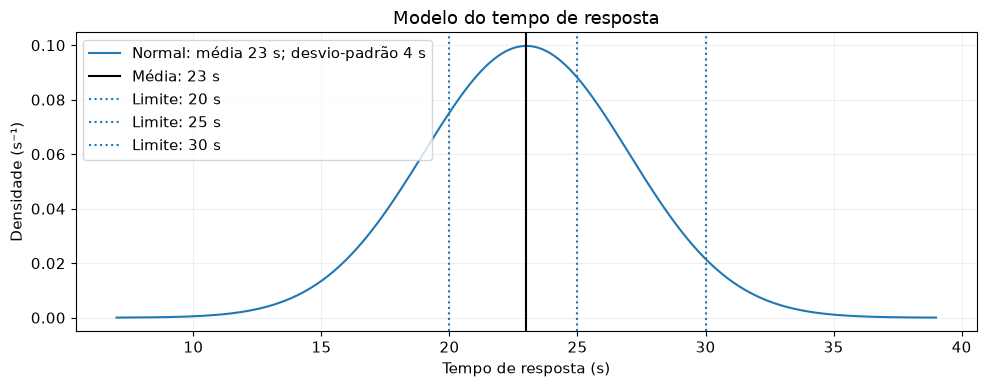

In [19]:
# DENSIDADE E POSIÇÕES DE INTERESSE
x_n = np.linspace(7, 39, 641)
fig, ax = plt.subplots()
ax.plot(x_n, modelo_x.pdf(x_n), label='Normal: média 23 s; desvio-padrão 4 s')
ax.axvline(mu, color='black', label='Média: 23 s')
for limite in [20, 25, 30]:
    ax.axvline(limite, linestyle=':', label=f'Limite: {limite} s')
ax.set(title='Modelo do tempo de resposta', xlabel='Tempo de resposta (s)', ylabel='Densidade (s⁻¹)')
ax.legend()
fig.tight_layout()
plt.show()

## 8. Padronização e escore z

### 8.1. Contexto

Retome 25, 20 e 30 segundos. **Quantos desvios-padrão cada limite está acima ou abaixo de 23 segundos?** Usaremos os mesmos limites do exercício 9 (Barbetta; Reis; Bornia, 2010, p. 159).

### 8.2. Fundamentação formal

$$
Z=\frac{X-\mu}{\sigma}\sim\mathcal{N}(0,1),\qquad
z=\frac{x-\mu}{\sigma},\qquad \sigma>0.
\tag{8.3}
$$

$Z:\Omega\to\mathbb{R}$ é a variável padronizada, definida sobre as mesmas execuções do algoritmo; $z$ é seu valor quando $X=x$. O quociente não tem unidade. Um escore positivo indica valor acima da média; negativo, abaixo; seu módulo indica a distância em desvios-padrão.

$$
\mathbb{P}(X\leq x)=\mathbb{P}\!\left(Z\leq\frac{x-\mu}{\sigma}\right).
\tag{8.4}
$$

A transformação é crescente, pois $\sigma>0$, e preserva a probabilidade do evento correspondente. $Z$ é Normal padrão **porque $X$ é Normal**. Padronizar uma variável qualquer não a torna Normal (Barbetta; Reis; Bornia, 2010, p. 155–156; Morettin; Bussab, 2010, p. 177–178).

### 8.3. Implementação sem pacote estatístico

Implemente a transformação (8.3), verificando `sigma > 0`. Calcule os escores de 25, 20 e 30 s e reutilize-os nos cálculos de probabilidade.

In [20]:
# PADRONIZAÇÃO
def padronizar(x, mu, sigma):
    if sigma <= 0:
        raise ValueError('O desvio-padrão deve ser positivo.')
    return (x - mu) / sigma

In [21]:
# ESCORES DOS LIMITES DO EXERCÍCIO
z_25 = padronizar(25, mu, sigma)
z_20 = padronizar(20, mu, sigma)
z_30 = padronizar(30, mu, sigma)

# APRESENTAÇÃO DOS ESCORES
linhas_z = []
for limite in limites_x:
    z = padronizar(limite, mu, sigma)
    linhas_z.append([limite, z])
display(pd.DataFrame(linhas_z, columns=['Tempo (s)', 'Escore z']))

,Tempo (s),Escore z
0,25,0.50
1,20,-0.75
2,30,1.75


### 8.4. Implementação com pacotes

Confira a igualdade entre `modelo_x.cdf(x)` e `stats.norm.cdf(z)`, que avaliam a acumulada nas escalas original e padronizada. Esta comparação verifica os parâmetros e a transformação; ambas as avaliações usam o SciPy (SciPy Community, [s. d.], verbete [`scipy.stats.norm`](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.norm.html)).

In [22]:
# CONFERÊNCIA DA ACUMULADA NAS DUAS ESCALAS
linhas_z_conf = []
for limite in limites_x:
    z = padronizar(limite, mu, sigma)
    prob_original = modelo_x.cdf(limite)
    prob_padronizada = stats.norm.cdf(z)
    diferenca = abs(prob_original - prob_padronizada)
    linhas_z_conf.append([limite, z, prob_original, prob_padronizada, diferenca])

# APRESENTAÇÃO DA CONFERÊNCIA
colunas_z_conf = ['Tempo (s)', 'Escore z', 'Acumulada original',
                  'Acumulada padronizada', 'Diferença absoluta']
display(pd.DataFrame(linhas_z_conf, columns=colunas_z_conf))

,Tempo (s),Escore z,Acumulada original,Acumulada padronizada,Diferença absoluta
0,25,0.50,0.691462,0.691462,0.0
1,20,-0.75,0.226627,0.226627,0.0
2,30,1.75,0.959941,0.959941,0.0


### 8.5. Aplicação e interpretação

**Exercício 9, capítulo 6: transformação dos limites** (Barbetta; Reis; Bornia, 2010, p. 159).

- 25 s: $z=(25-23)/4=0{,}5$, meio desvio-padrão acima da média.
- 20 s: $z=(20-23)/4=-0{,}75$, três quartos de desvio-padrão abaixo.
- 30 s: $z=(30-23)/4=1{,}75$, um desvio-padrão e três quartos acima.

O evento $20<X<30$ corresponde a $-0{,}75<Z<1{,}75$. As áreas são iguais nas duas escalas; as alturas das densidades têm unidades e valores distintos.

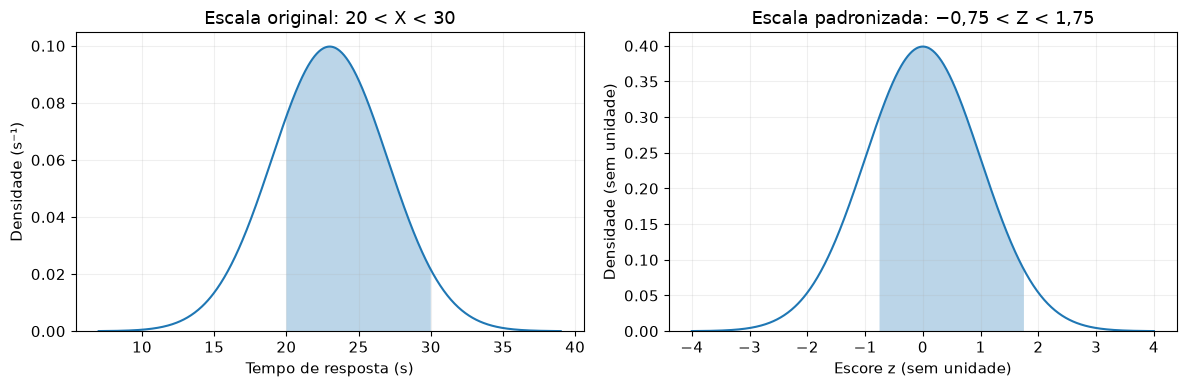

In [23]:
# MESMO EVENTO EM DUAS ESCALAS
z_n = (x_n - mu) / sigma
fig, eixos = plt.subplots(1, 2, figsize=(12, 4))
eixos[0].plot(x_n, modelo_x.pdf(x_n))
x_evento = np.linspace(20, 30, 201)
eixos[0].fill_between(x_evento, modelo_x.pdf(x_evento), alpha=0.3)
eixos[0].set(title='Escala original: 20 < X < 30', xlabel='Tempo de resposta (s)', ylabel='Densidade (s⁻¹)')
eixos[1].plot(z_n, stats.norm.pdf(z_n))
z_evento = (x_evento - mu) / sigma
eixos[1].fill_between(z_evento, stats.norm.pdf(z_evento), alpha=0.3)
eixos[1].set(title='Escala padronizada: −0,75 < Z < 1,75', xlabel='Escore z (sem unidade)', ylabel='Densidade (sem unidade)')
for ax in eixos:
    ax.set_ylim(bottom=0)
fig.tight_layout()
plt.show()

*Figura 10 — O mesmo evento antes e depois da padronização. Elaboração para a aula, a partir do exercício 9(b) de Barbetta, Reis e Bornia (2010, p. 159).*

## 9. Probabilidades com SciPy

### 9.1. Contexto

**Exercício 9, capítulo 6, itens (a)–(b):** calcule a probabilidade de o algoritmo responder (a) em menos de 25 s e (b) entre 20 e 30 s (Barbetta; Reis; Bornia, 2010, p. 159). Antes de calcular, identifique se o evento pede uma cauda, uma acumulada ou uma diferença de acumuladas.

### 9.2. Fundamentação formal

Na Normal padrão, a densidade e a acumulada são

$$
\phi(z)=\frac{1}{\sqrt{2\pi}}e^{-z^2/2},\qquad
\Phi(z)=\int_{-\infty}^{z}\phi(v)\,dv.
\tag{8.5}
$$

$\phi$ representa densidade; $\Phi$, probabilidade acumulada; $z$ é um escore e $v$ é a variável de integração. A altura de $\Phi$ já é uma probabilidade: não precisamos calcular uma área sob a curva da acumulada.

$$
\begin{aligned}
F_X(x)&=\Phi\!\left(\frac{x-\mu}{\sigma}\right),\\
\mathbb{P}(X>x)&=1-F_X(x),\\
\mathbb{P}(c<X\leq d)&=F_X(d)-F_X(c),\qquad c<d.
\end{aligned}
\tag{8.6}
$$

$c$ e $d$ são limites na escala original; $\mu$ e $\sigma$ são os parâmetros do algoritmo. Para uma variável contínua, as desigualdades estritas ou inclusivas nos extremos produzem a mesma probabilidade.

Pela simetria,

$$
\Phi(-z)=1-\Phi(z).
\tag{8.7}
$$

Essa identidade vale para qualquer escore real $z$. Valores negativos são fornecidos diretamente ao SciPy, com o próprio sinal (Barbetta; Reis; Bornia, 2010, p. 154–158; Morettin; Bussab, 2010, p. 177–178).

### 9.3. Implementação sem pacote estatístico

Formule os eventos pelas expressões acima e calcule os escores. Não implementaremos uma integração numérica própria para a acumulada Normal.

### 9.4. Implementação com pacotes

Use `cdf` para a probabilidade à esquerda, `sf` para a cauda direita e diferença de `cdf` para intervalos. Em caudas muito pequenas, `sf` evita a perda de precisão que pode ocorrer ao subtrair uma acumulada muito próxima de 1 (SciPy Community, [s. d.], verbete [`scipy.stats.norm`](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.norm.html)).

Reutilize os escores já calculados para conferir os itens do exercício nas duas escalas. Diferenças próximas de zero indicam concordância numérica entre essas representações.

In [24]:
# PROBABILIDADES DO EXERCÍCIO
prob_x_a = modelo_x.cdf(25)
prob_x_b = modelo_x.cdf(30) - modelo_x.cdf(20)

# CAUDA COMPLEMENTAR DO ITEM A
prob_x_direita = modelo_x.sf(25)

# APRESENTAÇÃO DOS RESULTADOS
print(f'P(X < 25) = {prob_x_a:.6f}')
print(f'P(20 < X < 30) = {prob_x_b:.6f}')
print(f'P(X > 25) = {prob_x_direita:.6f}')
print(f'Soma das duas caudas em 25: {prob_x_a + prob_x_direita:.6f}')

P(X < 25) = 0.691462
P(20 < X < 30) = 0.733313
P(X > 25) = 0.308538
Soma das duas caudas em 25: 1.000000


In [25]:
# PROBABILIDADES PADRONIZADAS
prob_z_a = stats.norm.cdf(z_25)
prob_z_b = stats.norm.cdf(z_30) - stats.norm.cdf(z_20)

# DIFERENÇAS ENTRE AS REPRESENTAÇÕES
print(f'Item (a), escala original: {prob_x_a:.6f}; padronizada: {prob_z_a:.6f}')
print(f'Item (b), escala original: {prob_x_b:.6f}; padronizada: {prob_z_b:.6f}')
print(f'Diferença absoluta no item (a): {abs(prob_x_a - prob_z_a):.2e}')
print(f'Diferença absoluta no item (b): {abs(prob_x_b - prob_z_b):.2e}')

Item (a), escala original: 0.691462; padronizada: 0.691462
Item (b), escala original: 0.733313; padronizada: 0.733313
Diferença absoluta no item (a): 0.00e+00
Diferença absoluta no item (b): 0.00e+00


### 9.5. Aplicação e interpretação

**Exercício 9(a–b):** (a) P(X < 25) ≈ **0,6915** e (b) P(20 < X < 30) ≈ **0,7333**. Sob o modelo, cerca de 69,15% das execuções ficam abaixo de 25 s e cerca de 73,33% ficam entre 20 e 30 s.

A cauda acima de 25 s é aproximadamente 0,3085 e complementa o item (a). Os cálculos nas escalas original e padronizada concordam, salvo possíveis diferenças de arredondamento. Esses percentuais descrevem execuções sob o modelo, sem garantir o resultado de uma execução individual.

**Evidências:** indicar o método utilizado em cada evento, conferir o complemento e a padronização e explicar as áreas destacadas abaixo. Na acumulada, ler a probabilidade pela altura; para um intervalo, subtrair duas alturas.

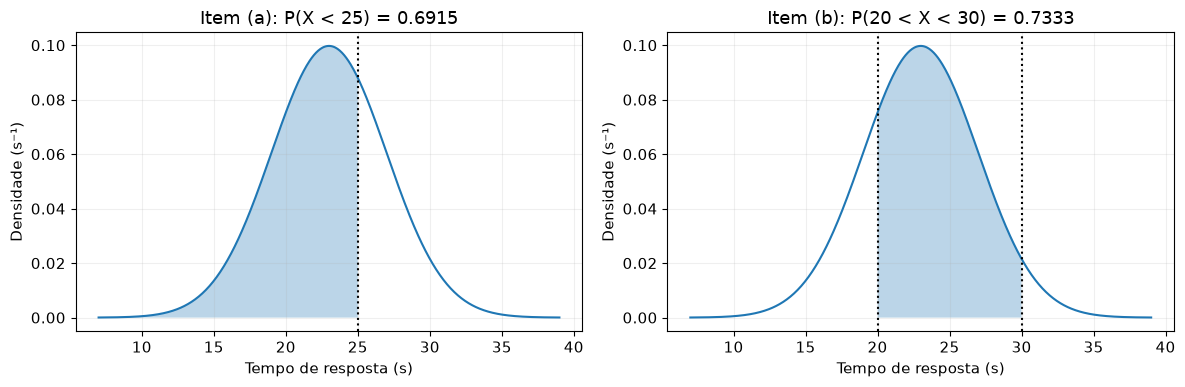

In [26]:
# ÁREAS DOS EVENTOS ORIGINAIS
fig, eixos = plt.subplots(1, 2, figsize=(12, 4))
for ax in eixos:
    ax.plot(x_n, modelo_x.pdf(x_n))
    ax.set(xlabel='Tempo de resposta (s)', ylabel='Densidade (s⁻¹)')
x_esquerda = np.linspace(7, 25, 361)
eixos[0].fill_between(x_esquerda, modelo_x.pdf(x_esquerda), alpha=0.3)
eixos[0].axvline(25, color='black', linestyle=':')
eixos[0].set_title(f'Item (a): P(X < 25) = {prob_x_a:.4f}')
eixos[1].fill_between(x_evento, modelo_x.pdf(x_evento), alpha=0.3)
eixos[1].axvline(20, color='black', linestyle=':')
eixos[1].axvline(30, color='black', linestyle=':')
eixos[1].set_title(f'Item (b): P(20 < X < 30) = {prob_x_b:.4f}')
fig.tight_layout()
plt.show()

*Figura 11 — Probabilidades dos itens (a–b) do exercício 9. Elaboração para a aula. A figura exibe de 7 a 39 s; o cálculo da cauda esquerda considera todos os valores abaixo de 25 s.*

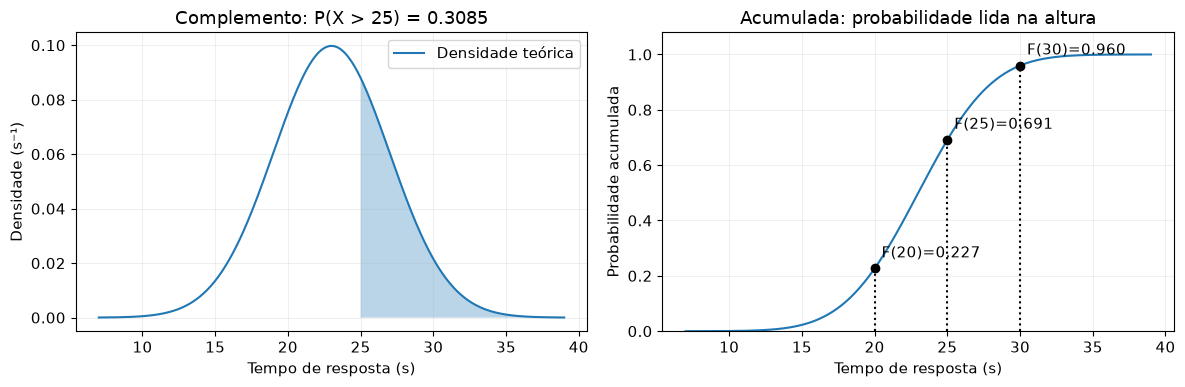

In [27]:
# CAUDA DIREITA
fig, eixos = plt.subplots(1, 2, figsize=(12, 4))
eixos[0].plot(x_n, modelo_x.pdf(x_n), label='Densidade teórica')
x_direita = np.linspace(25, 39, 281)
eixos[0].fill_between(x_direita, modelo_x.pdf(x_direita), alpha=0.3)
eixos[0].set(title=f'Complemento: P(X > 25) = {prob_x_direita:.4f}', xlabel='Tempo de resposta (s)', ylabel='Densidade (s⁻¹)')
eixos[0].legend()

# ALTURAS DA ACUMULADA
eixos[1].plot(x_n, modelo_x.cdf(x_n))
for limite in [20, 25, 30]:
    altura = modelo_x.cdf(limite)
    eixos[1].plot(limite, altura, 'o', color='black')
    eixos[1].vlines(limite, 0, altura, color='black', linestyle=':')
    eixos[1].annotate(f'F({limite})={altura:.3f}', (limite, altura), xytext=(5, 8), textcoords='offset points')
eixos[1].set(title='Acumulada: probabilidade lida na altura', xlabel='Tempo de resposta (s)', ylabel='Probabilidade acumulada', ylim=(0, 1.08))
fig.tight_layout()
plt.show()

*Figura 12 — Cauda complementar do item (a), densidade e alturas da acumulada nos limites do exercício 9. Elaboração para a aula. As caudas calculadas incluem os valores além do recorte exibido.*

## 10. Estudo e exercícios

### 10.1. Materiais didáticos

Leituras e documentação para estudo e revisão da aula.

- BARBETTA; REIS; BORNIA (2010), capítulo 6, seções 6.1 e 6.2.1–6.2.3: variáveis contínuas, densidade, acumulada, momentos e distribuições Uniforme, Exponencial e Normal.
- MORETTIN; BUSSAB (2010), capítulo 7: seção 7.4.1, pp. 174–175, para Uniforme; seção 7.4.2, pp. 176–178, para densidade, momentos, padronização e acumulada da Normal; seção 7.4.3, pp. 181–182, para Exponencial. Na Exponencial, a obra usa a escala $\beta=1/\lambda$.
- PINHEIRO et al. (2009), seção 4.4, pp. 111–118: densidade, acumulada, probabilidades de intervalos, Uniforme e Exponencial e sua relação com Poisson.
- SCIPY COMMUNITY ([s. d.]), documentação de [`scipy.stats.uniform`](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.uniform.html), [`scipy.stats.expon`](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.expon.html) e [`scipy.stats.norm`](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.norm.html): parametrização e métodos de densidade, acumulada, cauda superior, momentos e geração de amostras.

### 10.2. Vídeos explicativos

Vídeos em inglês para preparação ou revisão dos temas da aula.

**Distribuição Uniforme**

- JBSTATISTICS. [*Introduction to the Continuous Uniform Distribution*](https://www.youtube.com/watch?v=izE1dXrH5JA): densidade, média, variância e cálculo de probabilidades na Uniforme contínua.

**Distribuição Exponencial**

- TSITSIKLIS, John. MIT OpenCourseWare. [*08.6 Exponential Random Variables*](https://ocw.mit.edu/courses/res-6-012-introduction-to-probability-spring-2018/resources/exponential-random-variables/): introdução às variáveis aleatórias exponenciais.
- TSITSIKLIS, John. MIT OpenCourseWare. [*09.4 Memorylessness of the Exponential PDF*](https://ocw.mit.edu/courses/res-6-012-introduction-to-probability-spring-2018/resources/memorylessness-of-the-exponential-pdf/): propriedade de falta de memória da Exponencial.

**Distribuição Normal**

- STATQUEST WITH JOSH STARMER. [*The Normal Distribution, Clearly Explained!!!*](https://www.youtube.com/watch?v=rzFX5NWojp0): interpretação da curva Normal e do papel da média e do desvio-padrão.
- JBSTATISTICS. [*Standardizing Normally Distributed Random Variables*](https://www.jbstatistics.com/standardizing-normally-distributed-random-variables/): transformação de uma variável Normal para a escala da Normal padrão.
- TSITSIKLIS, John. MIT OpenCourseWare. [*08.9 Calculation of Normal Probabilities*](https://ocw.mit.edu/courses/res-6-012-introduction-to-probability-spring-2018/resources/calculation-of-normal-probabilities/): cálculo de probabilidades na distribuição Normal.

**Complemento sobre variáveis contínuas**

- STATQUEST WITH JOSH STARMER. [*Expected Values for Continuous Variables!!!*](https://www.youtube.com/watch?v=OSPr6G6Ka-U): complemento opcional sobre esperança de variáveis contínuas.

### 10.3. Exercícios indicados

Resolver computacionalmente, utilizando as implementações sem pacote estatístico e/ou métodos do SciPy.

- BARBETTA; REIS; BORNIA (2010), capítulo 6, exercício 1, itens (a)–(c), p. 146: Uniforme em $[0,1]$, densidade, acumulada, esperança e variância.
- BARBETTA; REIS; BORNIA (2010), capítulo 6, exercício 2, enunciado e itens (a)–(c), pp. 146–147: tempo de execução Uniforme entre 20 e 24 segundos; representação da densidade, probabilidade, esperança e variância.
- BARBETTA; REIS; BORNIA (2010), capítulo 6, exercício 6, itens (a)–(c), p. 152: vida útil Exponencial, probabilidades de cauda e intervalo e falta de memória.
- BARBETTA; REIS; BORNIA (2010), capítulo 6, exercício 8, itens (a)–(f), p. 158: probabilidades de caudas e intervalos na Normal padrão.
- BARBETTA; REIS; BORNIA (2010), capítulo 6, exercício 9, itens (a)–(b), p. 159: probabilidades para o tempo de execução de um algoritmo com modelo Normal.

## 11. Referências

1. BARBETTA, Pedro Alberto; REIS, Marcelo Menezes; BORNIA, Antonio Cezar. *Estatística para cursos de engenharia e informática*. 3. ed. São Paulo: Atlas, 2010. Cap. 6.
2. MORETTIN, Pedro Alberto; BUSSAB, Wilton de Oliveira. *Estatística básica*. 6. ed. São Paulo: Saraiva, 2010. Cap. 7, seções 7.4.1–7.4.3.
3. PINHEIRO, João Ismael D. et al. *Estatística básica: a arte de trabalhar com dados*. Rio de Janeiro: Elsevier, 2009. Seção 4.4.
4. SCIPY COMMUNITY. *scipy.stats.uniform*. [S. l.], [s. d.]. Disponível em: [documentação oficial](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.uniform.html). Acesso em: 29 out. 2026.
5. SCIPY COMMUNITY. *scipy.stats.expon*. [S. l.], [s. d.]. Disponível em: [documentação oficial](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.expon.html). Acesso em: 29 out. 2026.
6. SCIPY COMMUNITY. *scipy.stats.norm*. [S. l.], [s. d.]. Disponível em: [documentação oficial](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.norm.html). Acesso em: 29 out. 2026.
7. JBSTATISTICS. *Introduction to the Continuous Uniform Distribution*. YouTube, [s. d.]. Vídeo. Disponível em: [YouTube](https://www.youtube.com/watch?v=izE1dXrH5JA). Acesso em: 29 out. 2026.
8. STATQUEST WITH JOSH STARMER. *The Normal Distribution, Clearly Explained!!!*. YouTube, 2017. Vídeo. Disponível em: [YouTube](https://www.youtube.com/watch?v=rzFX5NWojp0). Acesso em: 29 out. 2026.
9. STATQUEST WITH JOSH STARMER. *Expected Values for Continuous Variables!!!*. YouTube, [s. d.]. Vídeo. Disponível em: [YouTube](https://www.youtube.com/watch?v=OSPr6G6Ka-U). Acesso em: 29 out. 2026.
10. JBSTATISTICS. *Standardizing Normally Distributed Random Variables*. [S. l.], [s. d.]. Vídeo. Disponível em: [JB Statistics](https://www.jbstatistics.com/standardizing-normally-distributed-random-variables/). Acesso em: 29 out. 2026.
11. TSITSIKLIS, John. *08.6 Exponential Random Variables*. In: *Introduction to Probability*. MIT OpenCourseWare, 2018. Vídeo. Disponível em: [MIT OpenCourseWare](https://ocw.mit.edu/courses/res-6-012-introduction-to-probability-spring-2018/resources/exponential-random-variables/). Acesso em: 29 out. 2026.
12. TSITSIKLIS, John. *09.4 Memorylessness of the Exponential PDF*. In: *Introduction to Probability*. MIT OpenCourseWare, 2018. Vídeo. Disponível em: [MIT OpenCourseWare](https://ocw.mit.edu/courses/res-6-012-introduction-to-probability-spring-2018/resources/memorylessness-of-the-exponential-pdf/). Acesso em: 29 out. 2026.
13. TSITSIKLIS, John. *08.9 Calculation of Normal Probabilities*. In: *Introduction to Probability*. MIT OpenCourseWare, 2018. Vídeo. Disponível em: [MIT OpenCourseWare](https://ocw.mit.edu/courses/res-6-012-introduction-to-probability-spring-2018/resources/calculation-of-normal-probabilities/). Acesso em: 29 out. 2026.
